**Notebook 06: H2 Machine Learning Analysis**

H2 Machine Learning Analysis

H2: A Random Forest model provides the highest spoofing detection accuracy in IoT baggage tracking data compared to other ML models.

RQ2: Which ML models are most effective at detecting spoofing in Internet of Things enabled baggage tracking data?

This notebook compares Logistic Regression, Support Vector Machine, and Random Forest using the prepared RFID baggage tracking data. The models are tested to see how well they identify spoofed scans.

BLUF: The analysis checks which model has the highest spoofing detection accuracy and how often the models make incorrect predictions.

Step 1: Connect and Review the Prepared RFID Data

The prepared RFID baggage tracking file was opened from the Praxis project folder. The scan records, baggage journeys, and spoofing labels were checked before the H2 analysis continued.

In [1]:
# Step 1: Connect and review the prepared RFID data

# Load the libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Set the main project folder
# Check where the prepared data folder is located
main_folder = os.getcwd()
if not os.path.isdir(os.path.join(main_folder, "06_Prepared_Data")):
    main_folder = os.path.dirname(main_folder)

# Set the prepared RFID file
prepared_file = os.path.join(main_folder, "06_Prepared_Data", "02_Prepared_RFID_Data.csv")

# Check that the prepared file is available
if not os.path.isfile(prepared_file):
    raise FileNotFoundError("Prepared RFID file not found. Check the 06_Prepared_Data folder and reopen the notebook from the project.")

# Load the prepared RFID data
h2_data = pd.read_csv(prepared_file)

# Review the prepared RFID records
print("RFID data loaded successfully.")
print("Scan records:", len(h2_data))
print("Baggage journeys:", h2_data["bag_id"].nunique())
print("Unique scan IDs:", h2_data["scan_id"].nunique())
print("Spoofing records:", (h2_data["spoofing_label"] == 1).sum())
print("Spoofed Reader scan status:", (h2_data["scan_status"] == "Spoofed Reader").sum())
print("Available fields:", h2_data.columns.tolist())

RFID data loaded successfully.
Scan records: 31575
Baggage journeys: 5000
Unique scan IDs: 31575
Spoofing records: 375
Spoofed Reader scan status: 375
Available fields: ['bag_id', 'tag_id', 'reader_id', 'reader_location', 'custody_point', 'timestamp', 'expected_sequence', 'actual_sequence', 'expected_next_point', 'actual_next_point', 'scan_status', 'route_type', 'transfer_status', 'journey_status', 'journey_abnormal_type', 'expected_reader_id', 'expected_reader_location', 'expected_timestamp', 'disruption_id', 'disruption_window', 'flight_id', 'route_id', 'origin', 'destination', 'scan_id', 'disruption_minutes', 'reader_match', 'location_match', 'sequence_match', 'time_difference_minutes', 'delayed_indicator', 'scan_gap_minutes', 'final_label', 'spoofing_label']


Step 2: Review the H2 Spoofing Data

The spoofing records were reviewed to see how the reader information compares with the known labels. A label of 1 means spoofing. A label of 0 means the scan was not marked as spoofing for this test. Other problems may still be present in those records.

In [2]:
# Step 2: Review the H2 spoofing data

# Check the reader IDs and spoofing labels
print("Reader IDs and spoofing labels:")
print(pd.crosstab(h2_data["reader_id"], h2_data["spoofing_label"]))

# Check the reader matches
print("\nReader matches and spoofing labels:")
print(pd.crosstab(h2_data["reader_match"], h2_data["spoofing_label"]))

# Review the spoofing records
print("\nReader information for spoofing records:")
spoofing_rows = h2_data[h2_data["spoofing_label"] == 1]
print(spoofing_rows[["reader_id", "expected_reader_id", "reader_match", "scan_status"]].value_counts())

Reader IDs and spoofing labels:
spoofing_label     0    1
reader_id                
RDR001          4948    0
RDR002          4932    0
RDR003          4958    0
RDR004          4966    0
RDR005          1489    0
RDR006          4951    0
RDR007          4956    0
RDR999             0  375

Reader matches and spoofing labels:
spoofing_label      0    1
reader_match              
0                   0  375
1               31200    0

Reader information for spoofing records:
reader_id  expected_reader_id  reader_match  scan_status   
RDR999     RDR002              0             Spoofed Reader    67
           RDR006              0             Spoofed Reader    66
           RDR001              0             Spoofed Reader    63
           RDR003              0             Spoofed Reader    60
           RDR007              0             Spoofed Reader    55
           RDR004              0             Spoofed Reader    50
           RDR005              0             Spoofed Reader    14

Step 3: Create the H2 Modeling Data

A copy of the prepared RFID data was made for the H2 test. The 375 spoofing scans were arranged into three test patterns involving reader identity, reader location, and scan timing. This keeps one unusual reader value from giving away the spoofing answer.

The original prepared file was not changed. The random setting of 42 was kept so the same patterns can be created again.

In [3]:
# Step 3: Create the H2 modeling data

# Make a copy of the prepared RFID data
h2_model_data = h2_data.copy()

# Convert the scan times
h2_model_data["timestamp"] = pd.to_datetime(h2_model_data["timestamp"])
h2_model_data["expected_timestamp"] = pd.to_datetime(h2_model_data["expected_timestamp"])

# Set the approved reader IDs
approved_readers = ["RDR001", "RDR002", "RDR003", "RDR004", "RDR005", "RDR006", "RDR007"]

# Set the random state
rng = np.random.default_rng(42)

# Find the spoofing records
spoofed_indices = h2_model_data.index[h2_model_data["spoofing_label"] == 1].to_numpy().copy()
rng.shuffle(spoofed_indices)

# Divide the spoofing records into three groups
unauthorized_indices, location_indices, timing_indices = np.array_split(spoofed_indices, 3)

# Add the spoofing pattern labels
h2_model_data["spoofing_pattern"] = "Non Spoofing"
h2_model_data.loc[unauthorized_indices, "spoofing_pattern"] = "Unauthorized Reader"
h2_model_data.loc[location_indices, "spoofing_pattern"] = "Cloned Reader Location"
h2_model_data.loc[timing_indices, "spoofing_pattern"] = "Replayed Reader Timing"

# Pattern 1: Use a different reader ID
for row_index in unauthorized_indices:
    expected_reader = h2_model_data.loc[row_index, "expected_reader_id"]
    available_readers = [reader for reader in approved_readers if reader != expected_reader]
    h2_model_data.loc[row_index, "reader_id"] = rng.choice(available_readers)

# Find the normal reader locations
valid_locations = h2_model_data.loc[
    (h2_model_data["spoofing_label"] == 0) & (h2_model_data["location_match"] == 1),
    "reader_location"
].dropna().unique().tolist()

# Pattern 2: Use the correct reader at a different location
for row_index in location_indices:
    expected_reader = h2_model_data.loc[row_index, "expected_reader_id"]
    expected_location = h2_model_data.loc[row_index, "expected_reader_location"]
    h2_model_data.loc[row_index, "reader_id"] = expected_reader
    available_locations = [place for place in valid_locations if place != expected_location]
    h2_model_data.loc[row_index, "reader_location"] = rng.choice(available_locations)

# Pattern 3: Change the scan time by 5 to 9 minutes
for row_index in timing_indices:
    h2_model_data.loc[row_index, "reader_id"] = h2_model_data.loc[row_index, "expected_reader_id"]
    h2_model_data.loc[row_index, "reader_location"] = h2_model_data.loc[row_index, "expected_reader_location"]
    timing_offset = int(rng.integers(5, 10))
    h2_model_data.loc[row_index, "timestamp"] = (
        h2_model_data.loc[row_index, "expected_timestamp"] + pd.Timedelta(minutes=timing_offset)
    )

# Update the reader, location, and sequence checks
h2_model_data["reader_match"] = (h2_model_data["reader_id"] == h2_model_data["expected_reader_id"]).astype(int)
h2_model_data["location_match"] = (h2_model_data["reader_location"] == h2_model_data["expected_reader_location"]).astype(int)
h2_model_data["sequence_match"] = (h2_model_data["actual_sequence"] == h2_model_data["expected_sequence"]).astype(int)

# Check the difference between the scan times
h2_model_data["time_difference_minutes"] = (
    (h2_model_data["timestamp"] - h2_model_data["expected_timestamp"]).dt.total_seconds().abs() / 60
)

# Flag delays longer than 15 minutes
h2_model_data["delayed_indicator"] = (h2_model_data["time_difference_minutes"] > 15).astype(int)

# Put the scans in time order and check the gaps
h2_model_data = h2_model_data.sort_values(["bag_id", "timestamp", "scan_id"]).copy()
h2_model_data["scan_gap_minutes"] = (
    h2_model_data.groupby("bag_id")["timestamp"].diff().dt.total_seconds() / 60
)

# Review the H2 working data
print("H2 working records:", len(h2_model_data))
print("Spoofing records:", (h2_model_data["spoofing_label"] == 1).sum())
print("\nSimulated spoofing patterns:")
print(h2_model_data["spoofing_pattern"].value_counts())
print("\nRDR999 in original data:", (h2_data["reader_id"] == "RDR999").sum())
print("RDR999 in H2 working copy:", (h2_model_data["reader_id"] == "RDR999").sum())

H2 working records: 31575
Spoofing records: 375

Simulated spoofing patterns:
spoofing_pattern
Non Spoofing              31200
Unauthorized Reader         125
Replayed Reader Timing      125
Cloned Reader Location      125
Name: count, dtype: int64

RDR999 in original data: 375
RDR999 in H2 working copy: 0


Step 4: Prepare the H2 Machine Learning Features

The 13 input fields were selected for the three models. These fields include reader, location, route, sequence, and timing information. The known spoofing label and fields that directly reveal the answer were not used as inputs.

The code uses X for the input fields and y for the known spoofing labels.

In [4]:
# Step 4: Prepare the H2 Machine Learning features

# Set the 13 input fields
h2_feature_fields = [
    "reader_id", "reader_location", "custody_point", "expected_sequence",
    "actual_sequence", "expected_next_point", "actual_next_point",
    "route_type", "transfer_status", "expected_reader_location",
    "time_difference_minutes", "delayed_indicator", "scan_gap_minutes"
]

# Set the model input data
X = h2_model_data[h2_feature_fields].copy()

# Set the known spoofing labels
y = h2_model_data["spoofing_label"].copy()

# Keep the bag IDs for separating journeys
groups = h2_model_data["bag_id"].copy()

# Set the text fields
categorical_features = [
    "reader_id", "reader_location", "custody_point", "expected_next_point",
    "actual_next_point", "route_type", "transfer_status", "expected_reader_location"
]

# Set the number fields
numerical_features = [
    "expected_sequence", "actual_sequence", "time_difference_minutes",
    "delayed_indicator", "scan_gap_minutes"
]

# Review the input fields and labels
print("Input fields:", len(h2_feature_fields))
print("Word/category fields:", len(categorical_features))
print("Number fields:", len(numerical_features))
print("\nSpoofing labels:")
print(y.value_counts().sort_index())
print("\nMissing entries in the input fields:")
print(X.isna().sum())

Input fields: 13
Word/category fields: 8
Number fields: 5

Spoofing labels:
spoofing_label
0    31200
1      375
Name: count, dtype: int64

Missing entries in the input fields:
reader_id                      0
reader_location                0
custody_point                  0
expected_sequence              0
actual_sequence                0
expected_next_point            0
actual_next_point              0
route_type                     0
transfer_status                0
expected_reader_location       0
time_difference_minutes        0
delayed_indicator              0
scan_gap_minutes            5000
dtype: int64


Step 5: Create the H2 Training and Testing Data

The baggage journeys were divided into training and testing groups. About 70 percent of the bags were used for training and 30 percent for testing. All scans from the same bag stayed in one group.

A random setting of 42 was used so the split can be repeated. The groups do not contain the same bags.

In [5]:
# Step 5: Create the H2 training and testing data

# Set the training and testing split
from sklearn.model_selection import GroupShuffleSplit
splitter = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)

# Separate the rows into two groups
train_index, test_index = next(splitter.split(X, y, groups=groups))

# Create the training data
X_train = X.iloc[train_index].copy()
y_train = y.iloc[train_index].copy()
groups_train = groups.iloc[train_index].copy()

# Create the testing data
X_test = X.iloc[test_index].copy()
y_test = y.iloc[test_index].copy()
groups_test = groups.iloc[test_index].copy()

# Check for bags in both groups
shared_bags = set(groups_train.unique()).intersection(set(groups_test.unique()))

# Review the training and testing counts
print("Training scan records:", len(X_train))
print("Testing scan records:", len(X_test))
print("Training baggage journeys:", groups_train.nunique())
print("Testing baggage journeys:", groups_test.nunique())
print("Bags found in both groups:", len(shared_bags))
print("\nTraining labels:")
print(y_train.value_counts().sort_index())
print("\nTesting labels:")
print(y_test.value_counts().sort_index())

Training scan records: 21058
Testing scan records: 10517
Training baggage journeys: 3500
Testing baggage journeys: 1500
Bags found in both groups: 0

Training labels:
spoofing_label
0    20794
1      264
Name: count, dtype: int64

Testing labels:
spoofing_label
0    10406
1      111
Name: count, dtype: int64


Step 6: Prepare the Machine Learning Inputs

The input fields were prepared so the models could read them. Missing values were filled in, words were changed into numbers, and number fields were put on a similar scale.

The preparation rules were learned from the training data. The same rules were then used on the testing data.

In [6]:
# Step 6: Prepare the Machine Learning inputs

# Load the preparation tools
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Fill missing text and turn words into numbers
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

# Fill missing numbers and adjust their scale
numerical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Set the preparation steps for each field type
preprocessor = ColumnTransformer([
    ("categorical", categorical_transformer, categorical_features),
    ("numerical", numerical_transformer, numerical_features)
])

# Prepare the training records
X_train_prepared = preprocessor.fit_transform(X_train)

# Prepare the testing records the same way
X_test_prepared = preprocessor.transform(X_test)

# Review the prepared input data
print("Prepared training records:", len(X_train_prepared))
print("Prepared testing records:", len(X_test_prepared))
print("Prepared model input columns:", X_train_prepared.shape[1])
print("Missing training values:", np.isnan(X_train_prepared).sum())
print("Missing testing values:", np.isnan(X_test_prepared).sum())

Prepared training records: 21058
Prepared testing records: 10517
Prepared model input columns: 46
Missing training values: 0
Missing testing values: 0


Step 7: Train the H2 Machine Learning Models

Logistic Regression, Support Vector Machine, and Random Forest were trained using the same prepared records. The original model settings were kept.

Spoofing records make up a small part of the data. The balanced class setting gives those records more weight during training. It does not add new spoofing scans.

In [7]:
# Step 7: Train the H2 Machine Learning models

# Load the three Machine Learning models
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

# Train Logistic Regression
logistic_model = LogisticRegression(max_iter=1000, class_weight="balanced")
logistic_model.fit(X_train_prepared, y_train)
logistic_predictions = logistic_model.predict(X_test_prepared)
print("Logistic Regression finished.")

# Train Support Vector Machine
svm_model = SVC(kernel="rbf", class_weight="balanced")
svm_model.fit(X_train_prepared, y_train)
svm_predictions = svm_model.predict(X_test_prepared)
print("Support Vector Machine finished.")

# Train Random Forest
random_forest_model = RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42)
random_forest_model.fit(X_train_prepared, y_train)
random_forest_predictions = random_forest_model.predict(X_test_prepared)
print("Random Forest finished.")

# Check the number of model predictions
print("\nTesting predictions for each model:")
print("Logistic Regression:", len(logistic_predictions))
print("SVM:", len(svm_predictions))
print("Random Forest:", len(random_forest_predictions))

Logistic Regression finished.
Support Vector Machine finished.
Random Forest finished.

Testing predictions for each model:
Logistic Regression: 10517
SVM: 10517
Random Forest: 10517


Step 8: Evaluate and Compare the H2 Models

The three models were checked using the same testing records. Accuracy, precision, recall, F1 score, false positive rate, false negative rate, and confusion matrix values were calculated.

Accuracy counts all correct predictions. Precision shows how many spoofing alerts were correct. Recall shows how many actual spoofing scans were found. The remaining measures help show which errors the models made.

In [8]:
# Step 8: Evaluate and compare the H2 models

# Load the evaluation tools
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Use the same calculation for each model
def evaluate_model(model_name, actual_values, predicted_values):
    # Count the correct and incorrect predictions
    tn, fp, fn, tp = confusion_matrix(actual_values, predicted_values).ravel()

    # Calculate accuracy, precision, recall, and F1 score
    accuracy = accuracy_score(actual_values, predicted_values)
    precision = precision_score(actual_values, predicted_values, zero_division=0)
    recall = recall_score(actual_values, predicted_values, zero_division=0)
    f1 = f1_score(actual_values, predicted_values, zero_division=0)

    # Calculate the false positive rate
    false_positive_rate = fp / (fp + tn) if fp + tn > 0 else 0

    # Calculate the false negative rate
    false_negative_rate = fn / (fn + tp) if fn + tp > 0 else 0

    # Record the results for this model
    return {
        "Model": model_name, "Accuracy": accuracy, "Precision": precision,
        "Recall": recall, "F1 Score": f1,
        "False Positive Rate": false_positive_rate,
        "False Negative Rate": false_negative_rate,
        "True Negatives": tn, "False Positives": fp,
        "False Negatives": fn, "True Positives": tp
    }

# Check the three models using the same measures
logistic_results = evaluate_model("Logistic Regression", y_test, logistic_predictions)
svm_results = evaluate_model("Support Vector Machine", y_test, svm_predictions)
random_forest_results = evaluate_model("Random Forest", y_test, random_forest_predictions)

# Create the model comparison table
h2_model_comparison = pd.DataFrame([logistic_results, svm_results, random_forest_results])
print("H2 model comparison:")
display(h2_model_comparison.round(4))

# Review the confusion matrices
print("\nLogistic Regression confusion matrix:\n", confusion_matrix(y_test, logistic_predictions))
print("\nSVM confusion matrix:\n", confusion_matrix(y_test, svm_predictions))
print("\nRandom Forest confusion matrix:\n", confusion_matrix(y_test, random_forest_predictions))

H2 model comparison:


,Model,Accuracy,Precision,Recall,F1 Score,False Positive Rate,False Negative Rate,True Negatives,False Positives,False Negatives,True Positives
0,Logistic Regression,0.8521,0.0407,0.5766,0.0761,0.1449,0.4234,8898,1508,47,64
1,Support Vector Machine,0.7267,0.0372,1.0000,0.0717,0.2762,0.0000,7532,2874,0,111
2,Random Forest,0.8584,0.0694,1.0000,0.1297,0.1431,0.0000,8917,1489,0,111



Logistic Regression confusion matrix:
 [[8898 1508]
 [  47   64]]

SVM confusion matrix:
 [[7532 2874]
 [   0  111]]

Random Forest confusion matrix:
 [[8917 1489]
 [   0  111]]


Step 9: Validate and Save the H2 Results

The model with the highest accuracy was identified from the comparison results. The model table and confusion matrix figures were created using the same testing data.

Copies of the results were saved in a separate review folder. The original Notebook 06 result files were not replaced. Simple gray colors were used for the figures.

Model with highest accuracy: Random Forest
Highest accuracy: 85.84 %
Random Forest precision: 6.94 %
Random Forest recall: 100.0 %
Random Forest false positives: 1489
H2 result on the original accuracy measure: Supported


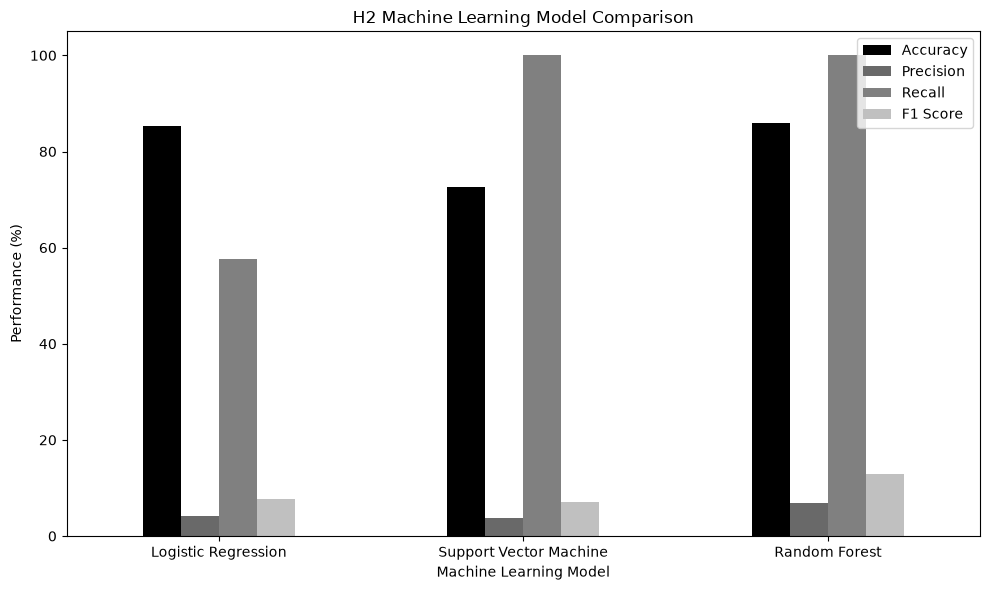

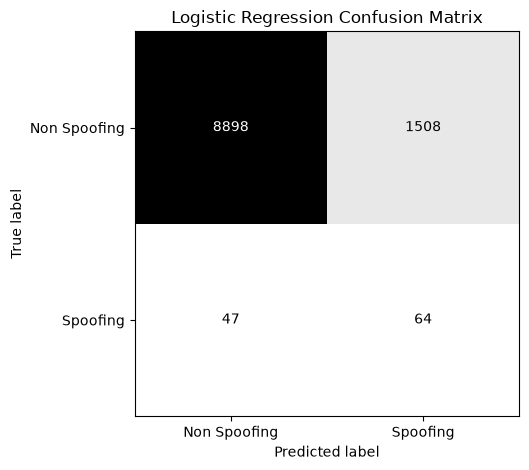

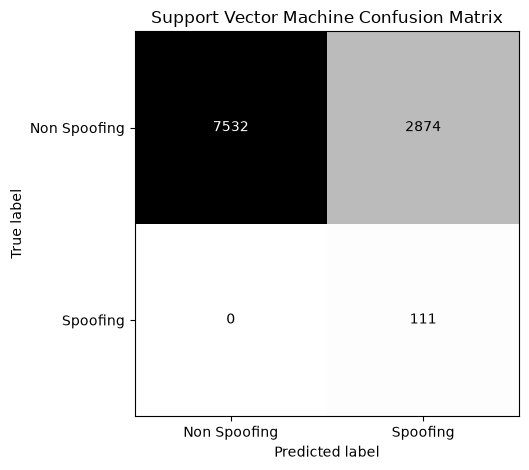

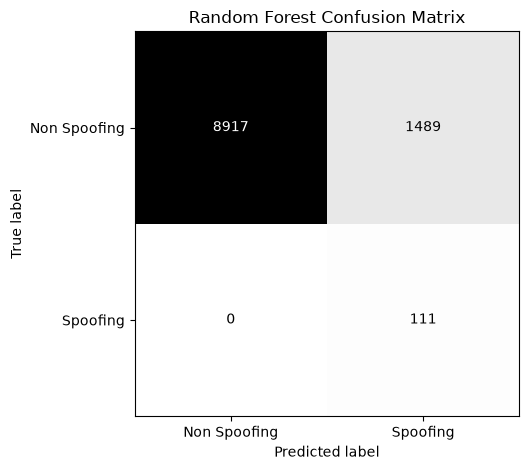

Original H2 comparison copies saved in: /workspaces/Aviation-Baggage-Cybersecurity-Research/08_H2_Results/Notebook_06_Simplified_Review


In [9]:
# Step 9: Validate and save the H2 results

# Load the confusion matrix tool
from sklearn.metrics import ConfusionMatrixDisplay

# Find the model with the highest accuracy
best_model = h2_model_comparison.sort_values("Accuracy", ascending=False).iloc[0]
h2_decision = "Supported" if best_model["Model"] == "Random Forest" else "Not Supported"

# Review the H2 findings
print("Model with highest accuracy:", best_model["Model"])
print("Highest accuracy:", round(best_model["Accuracy"] * 100, 2), "%")
print("Random Forest precision:", round(random_forest_results["Precision"] * 100, 2), "%")
print("Random Forest recall:", round(random_forest_results["Recall"] * 100, 2), "%")
print("Random Forest false positives:", random_forest_results["False Positives"])
print("H2 result on the original accuracy measure:", h2_decision)

# Set a separate folder for the results
results_folder = os.path.join(main_folder, "08_H2_Results", "Notebook_06_Simplified_Review")
os.makedirs(results_folder, exist_ok=True)

# Save the individual and combined model results
pd.DataFrame([logistic_results]).to_csv(os.path.join(results_folder, "h2_logistic_regression_results.csv"), index=False)
pd.DataFrame([svm_results]).to_csv(os.path.join(results_folder, "h2_svm_results.csv"), index=False)
pd.DataFrame([random_forest_results]).to_csv(os.path.join(results_folder, "h2_random_forest_results.csv"), index=False)
h2_model_comparison.to_csv(os.path.join(results_folder, "h2_model_comparison.csv"), index=False)

# Set the comparison chart colors
comparison_colors = ["black", "dimgray", "gray", "silver"]

# Set the confusion matrix color
confusion_colors = "Greys"

# Draw the model comparison chart
comparison_figure = h2_model_comparison[["Model", "Accuracy", "Precision", "Recall", "F1 Score"]].set_index("Model") * 100
comparison_figure.plot(kind="bar", figsize=(10, 6), color=comparison_colors)
plt.title("H2 Machine Learning Model Comparison")
plt.ylabel("Performance (%)")
plt.xlabel("Machine Learning Model")
plt.xticks(rotation=0)
plt.ylim(0, 105)
plt.tight_layout()
plt.savefig(os.path.join(results_folder, "h2_model_comparison.png"), dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# Draw the Logistic Regression confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test, logistic_predictions,
    display_labels=["Non Spoofing", "Spoofing"], values_format="d", cmap=confusion_colors, colorbar=False)
plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.savefig(os.path.join(results_folder, "h2_logistic_regression_confusion_matrix.png"), dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# Draw the SVM confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test, svm_predictions,
    display_labels=["Non Spoofing", "Spoofing"], values_format="d", cmap=confusion_colors, colorbar=False)
plt.title("Support Vector Machine Confusion Matrix")
plt.tight_layout()
plt.savefig(os.path.join(results_folder, "h2_svm_confusion_matrix.png"), dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# Draw the Random Forest confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test, random_forest_predictions,
    display_labels=["Non Spoofing", "Spoofing"], values_format="d", cmap=confusion_colors, colorbar=False)
plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.savefig(os.path.join(results_folder, "h2_random_forest_confusion_matrix.png"), dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("Original H2 comparison copies saved in:", results_folder)

Step 10: Calculate Additional H2 Model Measures

PR-AUC and ROC-AUC were added to check the models in another way. These measures use model scores instead of only the final spoofing predictions. Average Precision was also calculated because spoofing is uncommon in the testing data.

The same trained models and testing records were used. Two figures were created to show the results. No models were trained again in this step.

In [10]:
# Step 10: Calculate additional H2 model measures

# Load the additional evaluation tools
from sklearn.metrics import precision_recall_curve, average_precision_score, roc_auc_score, roc_curve, auc

# Get the spoofing scores for each model
# Class 1 is the spoofing label
logistic_scores = logistic_model.predict_proba(X_test_prepared)[:, 1]
random_forest_scores = random_forest_model.predict_proba(X_test_prepared)[:, 1]

# Use the SVM score from the trained model
svm_scores = svm_model.decision_function(X_test_prepared)

# Set the model names and scores
model_scores = {
    "Logistic Regression": logistic_scores,
    "Support Vector Machine": svm_scores,
    "Random Forest": random_forest_scores
}

# Create a list for the results
auc_results = []

# Calculate the three measures for each model
for model_name, scores in model_scores.items():
    precision, recall, _ = precision_recall_curve(y_test, scores)
    pr_auc = auc(recall, precision)                    # Area under the precision recall curve.
    average_precision = average_precision_score(y_test, scores)  # Related but different measure.
    roc_auc = roc_auc_score(y_test, scores)           # Area under the ROC curve.

    # Record the results for the model
    auc_results.append({
        "Model": model_name,
        "PR-AUC": pr_auc,
        "Average Precision": average_precision,
        "ROC-AUC": roc_auc
    })

# Display the additional H2 results
h2_auc_comparison = pd.DataFrame(auc_results)
print("H2 additional evaluation:")
display(h2_auc_comparison.round(4))
print("Spoofing share of the testing data:", round(y_test.mean() * 100, 2), "%")

# Save the additional H2 results
h2_auc_comparison.to_csv(os.path.join(results_folder, "h2_auc_metrics_supplement.csv"), index=False)
print("New metric table saved.")

H2 additional evaluation:


,Model,PR-AUC,Average Precision,ROC-AUC
0,Logistic Regression,0.0903,0.0913,0.6262
1,Support Vector Machine,0.0368,0.0375,0.8621
2,Random Forest,0.8697,0.8657,0.9807


Spoofing share of the testing data: 1.06 %
New metric table saved.


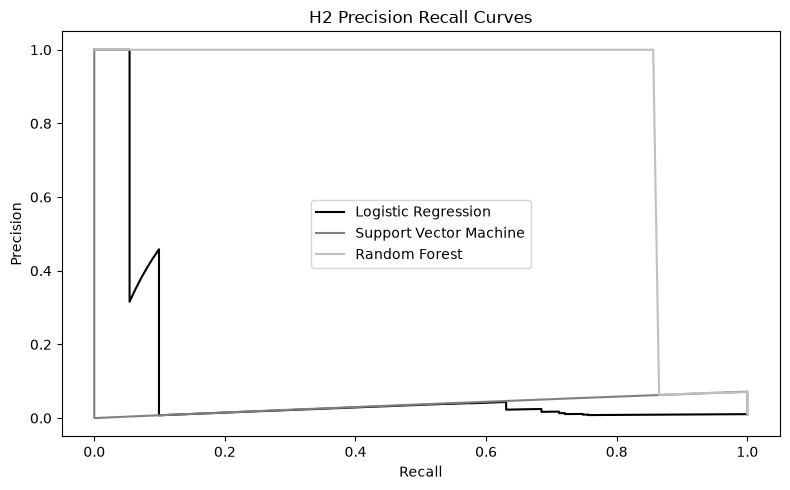

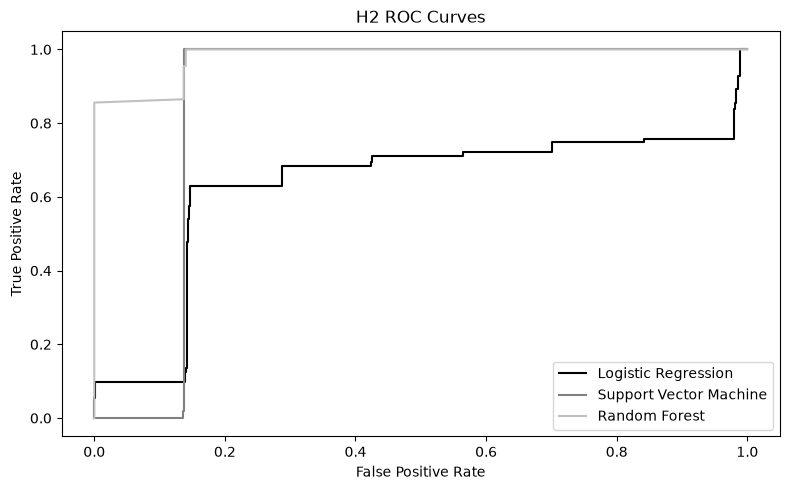

Additional H2 figures saved in: /workspaces/Aviation-Baggage-Cybersecurity-Research/08_H2_Results/Notebook_06_Simplified_Review


In [11]:
# Create the additional H2 figures

# Set the figure colors
model_colors = {
    "Logistic Regression": "black",
    "Support Vector Machine": "gray",
    "Random Forest": "silver"
}

# Figure 1: Show precision and recall
plt.figure(figsize=(8, 5))
for model_name, scores in model_scores.items():
    precision, recall, _ = precision_recall_curve(y_test, scores)
    plt.plot(recall, precision, label=model_name, color=model_colors[model_name])
plt.title("H2 Precision Recall Curves")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(results_folder, "h2_pr_curve.png"), dpi=300)
plt.show()
plt.close()

# Figure 2: Show the ROC results
plt.figure(figsize=(8, 5))
for model_name, scores in model_scores.items():
    false_positive_rate, true_positive_rate, _ = roc_curve(y_test, scores)
    plt.plot(false_positive_rate, true_positive_rate, label=model_name, color=model_colors[model_name])
plt.title("H2 ROC Curves")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(results_folder, "h2_roc_curve.png"), dpi=300)
plt.show()
plt.close()

print("Additional H2 figures saved in:", results_folder)

H2 Summary

The original H2 test compared Logistic Regression, Support Vector Machine, and Random Forest using the simulated RFID baggage tracking records.

Random Forest had the highest accuracy among the three models at 85.84 percent. It found all 111 spoofing scans in the testing data but also incorrectly flagged 1,489 other scans. Its recall was 100 percent and its precision was 6.94 percent.

The original accuracy comparison supports H2 within the simulated test. The large number of incorrect alerts limits what the result can show. A model that called every test scan nonspoofing would have about 98.94 percent accuracy but would miss every spoofing scan.

Step 10 adds PR-AUC, Average Precision, and ROC-AUC to help explain these results. The new scores should be taken from the completed Step 10 output before they are reported in the praxis.

Notebook 08 provides further checks on route differences and unfamiliar spoofing patterns. These tests use simulated data and do not establish performance in an operating airport.